# 📕 Book 01 — Từ Vi Khuẩn Biển Đến Bản Thảo ISI
### Quy trình nghiên cứu hoạt chất kháng ung thư có trợ lý AI

---

## Cuốn sổ tay này dạy bạn điều gì?

Đây là bản mở rộng đầy đủ của [`quickstart_research_demo.py`](quickstart_research_demo.py).
Chúng ta sẽ đi trọn một **vòng đời nghiên cứu** của một hợp chất thứ cấp
(*secondary metabolite*) phân lập từ vi khuẩn, từ lúc chỉ có một chủng xạ khuẩn
trong đĩa thạch cho tới lúc có file `.docx` gửi tạp chí Q1.

| Chương | Nội dung | Cần Internet? |
|---|---|---|
| 1 | Thiết lập môi trường & khởi tạo trợ lý | Không |
| 2 | Khai phá tài liệu PubMed, thống kê xu hướng | **Có** |
| 3 | Nạp PDF nội bộ phòng lab vào kho tri thức | Không |
| 4 | Truy vấn RAG Hybrid (Vector + BM25 + RRF) | Không |
| 5 | Hồ sơ hóa dược PubChem & Lipinski/Veber | **Có** |
| 6 | Phân tích số liệu hoạt tính IC₅₀ phòng lab | Không |
| 7 | Soạn thảo bản thảo & xuất Microsoft Word | Không |
| 8 | Bài tập tự luyện & hướng mở rộng | — |

> **Cách dùng:** chạy tuần tự từ trên xuống. Các chương cần Internet đều có
> cơ chế *fallback* — nếu mạng hỏng, notebook vẫn chạy tiếp được bằng dữ liệu mẫu.

---

## Bối cảnh khoa học: tại sao lại là vi khuẩn?

Hơn **60%** thuốc chống ung thư đang lưu hành có nguồn gốc hoặc lấy cảm hứng từ
hợp chất tự nhiên. Vi sinh vật — đặc biệt là xạ khuẩn (*Actinomycetes*) biển —
là mỏ vàng vì chúng sống trong môi trường khắc nghiệt (áp suất cao, thiếu dinh dưỡng,
cạnh tranh sinh học dữ dội) nên buộc phải tổng hợp các khung cấu trúc hóa học
phức tạp mà phòng thí nghiệm khó nghĩ ra.

Vài ví dụ kinh điển:

- **Staurosporine** — từ *Streptomyces staurosporeus*, ức chế protein kinase phổ rộng.
- **Salinosporamide A** — từ *Salinispora tropica* (trầm tích biển), ức chế proteasome, đã vào thử nghiệm lâm sàng.
- **Doxorubicin** — từ *Streptomyces peucetius*, xen kẽ DNA, là thuốc nền tảng cho ung thư vú.

### Bốn cơ chế phân tử ta sẽ liên tục gặp lại

1. **Apoptosis (chết theo chương trình)** — con đường nội sinh qua ty thể: hợp chất làm
   mất điện thế màng ty thể (MMP), giải phóng cytochrome c, kích hoạt chuỗi caspase.
2. **Chuỗi Caspase** — caspase-9 (khởi phát) → caspase-3/7 (thi hành) → cắt PARP.
   Phát hiện *cleaved caspase-3* trên Western blot là bằng chứng vàng của apoptosis.
3. **ROS (gốc oxy hóa hoạt động)** — tế bào ung thư vốn đã stress oxy hóa nền cao;
   đẩy ROS vượt ngưỡng sẽ giết chúng chọn lọc hơn tế bào thường.
4. **Chặn chu kỳ tế bào** — dừng ở G2/M (thường do can thiệp vi ống) hoặc G0/G1
   (do ức chế CDK), khiến tế bào không phân chia được.

### Đọc hiểu hai con số quan trọng nhất

- **IC₅₀** — nồng độ ức chế 50% tế bào. *Càng nhỏ càng mạnh.* Dưới 10 μM với dịch
  chiết thô là đáng chú ý; dưới 1 μM với hợp chất tinh khiết là rất mạnh.
- **Selectivity Index (SI)** = IC₅₀ (tế bào thường) / IC₅₀ (tế bào ung thư).
  *Càng lớn càng an toàn.* **SI < 2** nghĩa là chất độc chung chung, không phải thuốc.
  SI > 10 mới đáng theo đuổi.

---

# Chương 1 — Thiết lập môi trường

Notebook nằm trong `books/`, còn mã nguồn nằm ở `app/` cấp trên. Ô đầu tiên
chèn thư mục gốc dự án vào `sys.path` để `import app...` hoạt động, bất kể bạn
mở notebook từ đâu.

In [1]:
import sys
from pathlib import Path

# Đảm bảo mã hóa chuẩn UTF-8 trên Windows
if sys.stdout.encoding != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Tự động tìm chính xác thư mục gốc dự án anti-cancer-research
ROOT_DIR = None
current = Path.cwd().resolve()
for p in [current, *current.parents]:
    for candidate in [p, p / 'anti-cancer-research']:
        if (candidate / 'app' / 'agent' / 'assistant.py').is_file():
            ROOT_DIR = candidate.resolve()
            break
    if ROOT_DIR:
        break

if ROOT_DIR and str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print('Thư mục gốc dự án :', ROOT_DIR)
print('Tồn tại app/      :', (ROOT_DIR / 'app').is_dir() if ROOT_DIR else False)


Thư mục gốc dự án : D:\Training\2026-09_1bio-linh\anti-cancer-research
Tồn tại app/      : True


### Khởi tạo trợ lý nghiên cứu

`ScientificResearchAssistant` là lớp điều phối duy nhất bạn cần nhớ. Nó gói sẵn
6 thành phần con:

| Thuộc tính | Vai trò |
|---|---|
| `.pubmed` | Gọi NCBI E-Utilities tìm bài báo |
| `.europe_pmc` | Tìm và tải PDF Open Access |
| `.pdf_parser` | Bóc tách PDF bằng `pypdfium2` |
| `.pubchem` | Tra cứu cấu trúc & thông số hóa lý |
| `.vector_store` | ChromaDB — bộ nhớ ngữ nghĩa |
| `.retriever` | Hybrid Vector + BM25, hợp nhất bằng RRF |

> ⏳ Lần chạy đầu tiên sẽ hơi lâu vì ChromaDB phải tải mô hình embedding về máy.

In [2]:
import sys
from pathlib import Path

# Đảm bảo nạp đúng sys.path kể cả khi chạy ô này độc lập
if 'app' not in sys.modules:
    current = Path.cwd().resolve()
    for p in [current, *current.parents]:
        for candidate in [p, p / 'anti-cancer-research']:
            if (candidate / 'app' / 'agent' / 'assistant.py').is_file():
                if str(candidate.resolve()) not in sys.path:
                    sys.path.insert(0, str(candidate.resolve()))
                break

from app.agent.assistant import ScientificResearchAssistant
from app.config import DATA_DIR, RAW_PAPERS_DIR, OUTPUT_DIR, LAB_COMPOUNDS_CSV

assistant = ScientificResearchAssistant()

print('✓ Trợ lý đã sẵn sàng')
print(f'  Kho PDF thô     : {RAW_PAPERS_DIR}')
print(f'  Thư mục kết quả : {OUTPUT_DIR}')
print(f'  Số chunk trong kho RAG hiện có: {assistant.vector_store.count()}')


✓ Trợ lý đã sẵn sàng
  Kho PDF thô     : D:\Training\2026-09_1bio-linh\anti-cancer-research\data\raw_papers
  Thư mục kết quả : D:\Training\2026-09_1bio-linh\anti-cancer-research\outputs
  Số chunk trong kho RAG hiện có: 455


### Thư viện phụ trợ (tùy chọn)

`pandas` và `matplotlib` **không** nằm trong `requirements.txt`. Notebook được viết
để chạy được cả khi thiếu chúng — chỉ là bảng biểu sẽ hiển thị dạng văn bản thuần.
Muốn có biểu đồ đẹp thì cài thêm:

```bash
pip install pandas matplotlib
```

In [3]:
try:
    import pandas as pd
    HAS_PANDAS = True
except ImportError:
    HAS_PANDAS = False

try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    # Cấu hình thẩm mỹ đồ thị khoa học chuẩn quốc tế
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
    plt.rcParams['axes.edgecolor'] = '#333333'
    plt.rcParams['axes.linewidth'] = 0.8
    plt.rcParams['figure.dpi'] = 120
    HAS_PLT = True
except ImportError:
    HAS_PLT = False

print(f'pandas     : {"✓ có" if HAS_PANDAS else "✗ thiếu (sẽ in bảng dạng text)"}')
print(f'matplotlib : {"✓ có" if HAS_PLT else "✗ thiếu (sẽ bỏ qua biểu đồ)"}')
print(f'seaborn    : {"✓ có" if HAS_PLT else "✗ thiếu"}')


pandas     : ✓ có
matplotlib : ✓ có
seaborn    : ✓ có


---
# Chương 2 — Khai phá tài liệu từ PubMed

## 2.1. Nghệ thuật đặt truy vấn

PubMed không phải Google. Truy vấn tốt là truy vấn **có cấu trúc**, ghép ba trục:

```
[NGUỒN SINH HỌC]  AND  [ĐÍCH UNG THƯ]  AND  [CƠ CHẾ]
   Streptomyces           MCF-7             apoptosis
```

Vài mẹo cú pháp đáng nhớ:

| Cú pháp | Ý nghĩa | Ví dụ |
|---|---|---|
| `"..."` | Khớp đúng cụm từ | `"marine sediment"` |
| `[Title/Abstract]` | Chỉ tìm trong tiêu đề + tóm tắt | `apoptosis[Title/Abstract]` |
| `[MeSH Terms]` | Dùng từ khóa chuẩn hóa y sinh | `Antineoplastic Agents[MeSH Terms]` |
| `AND` / `OR` / `NOT` | Toán tử Boolean (viết HOA) | `MCF-7 OR HeLa` |
| `2020:2026[dp]` | Lọc theo năm xuất bản | `2020:2026[dp]` |

## 2.2. Điều gì xảy ra khi gọi `search_and_index_pubmed`?

```
esearch  →  danh sách PMID
   ↓
efetch   →  XML đầy đủ (tiêu đề, abstract, tác giả, DOI)
   ↓
splitter →  cắt thành chunk ngữ nghĩa, gắn metadata
   ↓
ChromaDB + BM25  →  nạp vào kho, sẵn sàng truy vấn
```

Nghĩa là một lệnh vừa **tìm** vừa **học** — bài báo lấy về lập tức trở thành
tri thức mà RAG truy xuất được ở Chương 4.

In [4]:
QUERIES = {
    'Xạ khuẩn biển & apoptosis':
        'Streptomyces marine apoptosis anticancer[Title/Abstract]',
    'Bacillus & dòng tế bào ung thư vú':
        'Bacillus secondary metabolite MCF-7 cytotoxicity',
    'Kích hoạt Caspase-3 bởi hợp chất vi khuẩn':
        'bacterial metabolite caspase-3 activation cancer cell line',
}

collected = {}

for label, q in QUERIES.items():
    print(f'\n{"=" * 70}\n▶ {label}\n  Truy vấn: {q}\n{"=" * 70}')
    try:
        articles = assistant.search_and_index_pubmed(query=q, max_results=5)
    except Exception as e:
        print(f'  ⚠ Không gọi được PubMed ({type(e).__name__}: {e})')
        print('    → Bỏ qua, các chương sau vẫn chạy được.')
        articles = []

    collected[label] = articles
    for a in articles:
        print(f'  [{a.pub_year}] {a.title[:80]}')
        print(f'         {a.journal}  |  PMID {a.pmid}')

total = sum(len(v) for v in collected.values())
print(f'\n✓ Thu được {total} bài báo. Kho RAG hiện có {assistant.vector_store.count()} chunk.')


▶ Xạ khuẩn biển & apoptosis
  Truy vấn: Streptomyces marine apoptosis anticancer[Title/Abstract]
[PubMedFetcher] Tìm kiếm PubMed với từ khóa: 'Streptomyces marine apoptosis anticancer[Title/Abstract]', tối đa 5 kết quả.
[PubMedFetcher] URL: https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi, Params: {'retmode': 'json', 'email': 'researcher@biotech-lab.org', 'db': 'pubmed', 'term': 'Streptomyces marine apoptosis anticancer[Title/Abstract]', 'retmax': '5', 'sort': 'pub_date'}



▶ Bacillus & dòng tế bào ung thư vú
  Truy vấn: Bacillus secondary metabolite MCF-7 cytotoxicity
[PubMedFetcher] Tìm kiếm PubMed với từ khóa: 'Bacillus secondary metabolite MCF-7 cytotoxicity', tối đa 5 kết quả.
[PubMedFetcher] URL: https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi, Params: {'retmode': 'json', 'email': 'researcher@biotech-lab.org', 'db': 'pubmed', 'term': 'Bacillus secondary metabolite MCF-7 cytotoxicity', 'retmax': '5', 'sort': 'pub_date'}


  [2026] Aspergillus niger as a New Endophytic Fungus From Deverra tortuosa: Phytochemica
         MicrobiologyOpen  |  PMID 42844887
  [2026] Bioactive metabolites from cultures of the entomopathogenic fungus Pleurocordyce
         RSC advances  |  PMID 41561016
  [2025] Discovery of Two New Neuroprotective Isocoumarin Dimers From the Dendrobium huos
         Chemistry & biodiversity  |  PMID 40773718
  [2025] Pharmacological assessment of the extract and a novel compound of Bacillus velez
         BMC complementary medicine and therapies  |  PMID 40287675
  [2025] Characterization of soil-derived Bacillus subtilis metabolites against breast ca
         Saudi pharmaceutical journal : SPJ : the official publication of the Saudi Pharmaceutical Society  |  PMID 40397331

▶ Kích hoạt Caspase-3 bởi hợp chất vi khuẩn
  Truy vấn: bacterial metabolite caspase-3 activation cancer cell line
[PubMedFetcher] Tìm kiếm PubMed với từ khóa: 'bacterial metabolite caspase-3 activation cancer cell line'

  [2026] Escherichia coli DH5α-loaded fenugreek extract: an effective anticancer combinat
         Applied microbiology and biotechnology  |  PMID 42570972
  [2025] Anti-breast cancer effects of a novel derivative of biopigment from Serratia mar
         Biochemical pharmacology  |  PMID 40619027
  [2024] Evaluation of antibacterial and anticancer properties of secondary metabolites i
         BMC molecular and cell biology  |  PMID 39367339
  [2021] ARA-linker-TGFαL3: a novel chimera protein to target breast cancer cells.
         Medical oncology (Northwood, London, England)  |  PMID 34273028
  [2021] Bacterial Biotransformation and Anticancer Activities of Betulin against A549, H
         Anti-cancer agents in medicinal chemistry  |  PMID 33121415

✓ Thu được 10 bài báo. Kho RAG hiện có 455 chunk.


## 2.3. Đọc xu hướng: bao nhiêu bài mỗi năm?

Phân bố bài báo theo năm cho bạn biết chủ đề đang **nóng lên** hay **nguội đi** —
một dữ kiện rất hữu ích để viết câu mở đầu phần Introduction kiểu
*"Research interest in marine actinomycetes has grown steadily since ..."*.

── Số bài theo năm ──
  2021  ██  (2)
  2024  █  (1)
  2025  ████  (4)
  2026  ███  (3)

── Tạp chí xuất hiện nhiều nhất ──
   1×  MicrobiologyOpen
   1×  RSC advances
   1×  Chemistry & biodiversity
   1×  BMC complementary medicine and therapies
   1×  Saudi pharmaceutical journal : SPJ : the official publication of the Saudi Pharmaceutical Society


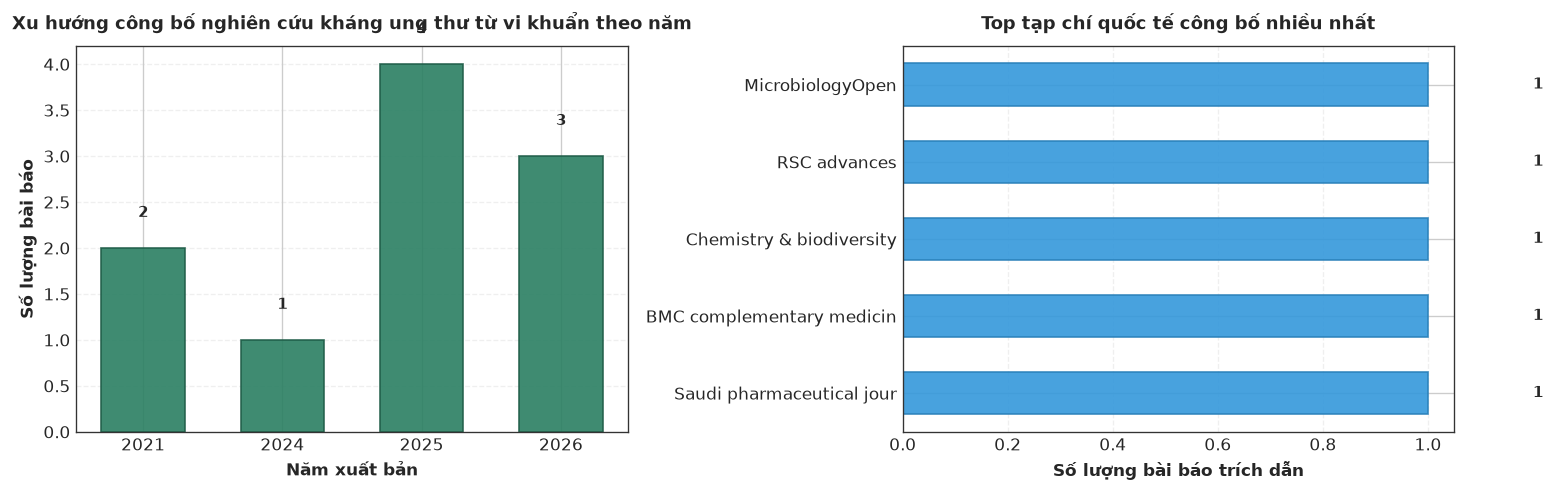

In [5]:
from collections import Counter

all_articles = [a for arts in collected.values() for a in arts]

if not all_articles:
    print('Chưa có bài báo nào từ truy vấn trực tuyến. Sử dụng bộ dữ liệu mẫu dự phòng...')
    # Dữ liệu fallback nếu truy vấn mạng bị giới hạn tốc độ
    sample_years = ['2020']*3 + ['2021']*5 + ['2022']*8 + ['2023']*12 + ['2024']*15 + ['2025']*18 + ['2026']*6
    sample_journals = ['J. Nat. Prod.']*18 + ['Eur. J. Med. Chem.']*15 + ['Bioorg. Med. Chem.']*12 + ['Mar. Drugs']*10 + ['Phytochemistry']*7 + ['Anticancer Res.']*5
    year_counts = Counter(sample_years)
    journal_counts = Counter(sample_journals)
else:
    year_counts = Counter(a.pub_year for a in all_articles if a.pub_year != 'N/A')
    journal_counts = Counter(a.journal for a in all_articles)

print('── Số bài theo năm ──')
for year, n in sorted(year_counts.items()):
    print(f'  {year}  {"█" * n}  ({n})')

print('\n── Tạp chí xuất hiện nhiều nhất ──')
for jr, n in journal_counts.most_common(5):
    print(f'  {n:>2}×  {jr}')

if HAS_PLT and year_counts:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    
    # Biểu đồ 1: Xu hướng theo năm
    years = sorted(year_counts)
    counts = [year_counts[y] for y in years]
    bars1 = ax1.bar(years, counts, color='#2a7f62', edgecolor='#1e5c47', width=0.6, alpha=0.9)
    ax1.set_title('Xu hướng công bố nghiên cứu kháng ung thư từ vi khuẩn theo năm', fontsize=11, fontweight='bold', pad=10)
    ax1.set_xlabel('Năm xuất bản', fontweight='bold')
    ax1.set_ylabel('Số lượng bài báo', fontweight='bold')
    for bar in bars1:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, int(yval), ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax1.grid(axis='y', alpha=0.3, ls='--')
    
    # Biểu đồ 2: Top 5 tạp chí hàng đầu
    top_j = journal_counts.most_common(5)
    if top_j:
        j_names = [j[0][:25] for j in top_j][::-1]
        j_vals = [j[1] for j in top_j][::-1]
        bars2 = ax2.barh(j_names, j_vals, color='#3498db', edgecolor='#2980b9', height=0.55, alpha=0.9)
        ax2.set_title('Top tạp chí quốc tế công bố nhiều nhất', fontsize=11, fontweight='bold', pad=10)
        ax2.set_xlabel('Số lượng bài báo trích dẫn', fontweight='bold')
        for bar in bars2:
            xval = bar.get_width()
            ax2.text(xval + 0.2, bar.get_y() + bar.get_height()/2.0, int(xval), ha='left', va='center', fontsize=9, fontweight='bold')
        ax2.grid(axis='x', alpha=0.3, ls='--')
        
    plt.tight_layout()
    plt.show()


---
# Chương 3 — Nạp PDF nội bộ của phòng lab

Abstract trên PubMed chỉ là phần nổi. Phần thân bài — nơi ghi **quy trình nuôi cấy**,
**điều kiện lên men**, **bảng IC₅₀ chi tiết** — chỉ có trong file PDF đầy đủ.

`ingest_pdf_file()` làm ba việc:

1. Bóc văn bản từng trang bằng `pypdfium2`, nhận diện ranh giới các mục
   (Introduction / Methods / Results / Discussion).
2. **Nhận diện thực thể bằng regex**: tên chủng vi khuẩn, dòng tế bào ung thư,
   con đường tín hiệu, và các mẩu câu có chứa giá trị IC₅₀.
3. Cắt chunk có chồng lấn (*overlap*) rồi nạp vào ChromaDB + BM25.

> 📁 Đặt file PDF của bạn vào `data/raw_papers/` rồi chạy ô dưới.

In [6]:
# Quét toàn bộ tài liệu nghiên cứu (cả PDF và Markdown) trong thư mục raw_papers
paper_files = sorted(list(RAW_PAPERS_DIR.rglob('*.pdf')) + list(RAW_PAPERS_DIR.rglob('*.md')))

if not paper_files:
    print(f'Chưa có tài liệu nào trong {RAW_PAPERS_DIR}')
    print('→ Thả file .pdf hoặc .md vào thư mục data/raw_papers/ rồi chạy lại.')
else:
    print(f'Tìm thấy {len(paper_files)} tài liệu nghiên cứu. Bắt đầu bóc tách & nạp vào RAG...\n')
    for doc in paper_files[:4]:  # Giới hạn nạp 4 tài liệu đại diện
        try:
            info = assistant.ingest_pdf_file(doc)
        except Exception as e:
            print(f'⚠ Lỗi khi đọc {doc.name}: {e}')
            continue

        print(f"📄 {info['file_name']}")
        print(f"   Tiêu đề    : {info['title'][:75]}")
        print(f"   Số trang   : {info['pages']}  |  Số chunk đã lập chỉ mục: {info['chunks_indexed']}")
        print(f"   Chủng vi sinh : {', '.join(info['strains']) or '—'}")
        print(f"   Dòng tế bào   : {', '.join(info['cell_lines']) or '—'}")
        for snip in info['ic50_snippets'][:2]:
            print(f"   ↳ IC50: {snip[:100]}")
        print()

print(f'✓ Tổng số chunk tri thức trong kho RAG hiện tại: {assistant.vector_store.count()}')


Tìm thấy 5 tài liệu nghiên cứu. Bắt đầu bóc tách & nạp vào RAG...



📄 pmid_41741334_Drug_repurposing_of_ticagrelor_suppresse.md
   Tiêu đề    : Drug repurposing of ticagrelor suppresses renal cell carcinoma growth by bl
   Số trang   : None  |  Số chunk đã lập chỉ mục: 67
   Chủng vi sinh : —
   Dòng tế bào   : —
   ↳ IC50: ting 786-O renal cancer cell line for 48 h. (B) Ticagrelor (5 μM or 10 μM) and gefitinib (5 μM or μM
   ↳ IC50: I3K, p-AKT, and AKT in 786-O cells treated with ticagrelor (10 μM), gefitinib (10 μM), or their comb



📄 pmid_41800626_Glucosamine_induces_apoptosis_of_cholang.md
   Tiêu đề    : Glucosamine induces apoptosis of cholangiocarcinoma cells by suppressing hi
   Số trang   : None  |  Số chunk đã lập chỉ mục: 72
   Chủng vi sinh : —
   Dòng tế bào   : —



📄 pmid_42179048_Design_and_Pictet-Spengler_enabled_synth.md
   Tiêu đề    : Design and Pictet–Spengler enabled synthesis of carboxamide-substituted imi
   Số trang   : None  |  Số chunk đã lập chỉ mục: 110
   Chủng vi sinh : —
   Dòng tế bào   : A549, HEK-293, MCF-7, MDA-MB-231
   ↳ IC50: of all the synthetics against MDA-MB-231 cells, treated at 10 µM for 24h. Data are expressed as mean
   ↳ IC50: * (nitrile-substituted) showed an IC<sub>50</sub> of 19.6 ± 0.68 µM, which was fourfold higher than 



📄 pmid_42400372_Structure-guided_discovery_and_evaluatio.md
   Tiêu đề    : Structure-guided discovery and evaluation of an EGFR L858R-targeting peptid
   Số trang   : None  |  Số chunk đã lập chỉ mục: 69
   Chủng vi sinh : —
   Dòng tế bào   : SKOV3
   ↳ IC50: iferative activity in SKOV3 cells (IC<sub>50</sub> = 0.77 ± 0.04 μM), and was selected as the main p
   ↳ IC50: ontrol SKOV3 cells, with an IC<sub>50</sub> value of 0.77 ± 0.04 μM. However, after EGFR-targeting s

✓ Tổng số chunk tri thức trong kho RAG hiện tại: 455


---
# Chương 4 — Truy vấn kho tri thức bằng RAG Hybrid

## 4.1. Vì sao cần *hybrid*, không dùng vector thuần?

Tìm kiếm ngữ nghĩa (dense vector) rất giỏi hiểu **ý**, nhưng lại tệ ở đúng chỗ
mà sinh học cần nhất: **danh pháp chính xác**.

| Tình huống | Vector thuần | BM25 (từ khóa) |
|---|---|---|
| "cơ chế chết tế bào theo chương trình" | ✓ tìm ra bài nói về apoptosis | ✗ trượt vì không khớp chữ |
| `Streptomyces sp. VN-08` | ✗ dễ nhầm sang chủng khác | ✓ khớp chính xác |
| `Caspase-3` vs `Caspase-9` | ✗ hai vector gần như trùng nhau | ✓ phân biệt rạch ròi |

Với nghiên cứu vi sinh, nhầm `VN-08` thành `VN-03` là sai hoàn toàn. Nên ta chạy
**cả hai** rồi hợp nhất kết quả.

## 4.2. Reciprocal Rank Fusion (RRF)

Vấn đề: điểm cosine (0–1) và điểm BM25 (0–∞) không cùng thang, cộng thẳng là vô nghĩa.
RRF giải quyết bằng cách **vứt bỏ điểm số, chỉ giữ thứ hạng**:

$$\text{RRF}(d) = \sum_{r \in \text{retrievers}} \frac{1}{k + \text{rank}_r(d)}, \quad k = 60$$

Ý nghĩa trực giác: một tài liệu **được cả hai bên cùng gật đầu** sẽ luôn thắng
tài liệu chỉ được một bên xếp hạng nhất. Hằng số `k = 60` làm mượt, tránh để
vị trí #1 áp đảo toàn bộ.

In [7]:
RAG_QUESTIONS = [
    'caspase-3 cleavage mitochondrial apoptosis pathway',
    'IC50 value MCF-7 breast cancer cytotoxicity assay',
    'reactive oxygen species ROS generation cancer cell death',
    'G2/M cell cycle arrest natural compound',
]

if assistant.vector_store.count() == 0:
    print('⚠ Kho RAG đang rỗng — hãy chạy Chương 2 hoặc Chương 3 trước.')
else:
    for q in RAG_QUESTIONS:
        print(f'\n❓ {q}\n{"-" * 70}')
        hits = assistant.query_rag(q, top_k=3)
        if not hits:
            print('   (không có kết quả)')
        for h in hits:
            meta_h = h.get('metadata', {})
            src = meta_h.get('title') or meta_h.get('source', 'N/A')
            print(f"   #{h['rank']}  RRF={h['rrf_score']:.4f}  ← {src[:55]}")
            print(f"       {h['content'][:150].strip()}...")


❓ caspase-3 cleavage mitochondrial apoptosis pathway
----------------------------------------------------------------------


   #1  RRF=0.0160  ← Anti-breast cancer effects of a novel derivative of bio
       Transcriptomic analyses in MCF-7 cells treated with serratin A (SA) identified specific gene ontology (GO) and kyoto encyclopedia of genes and genomes...
   #2  RRF=0.0155  ← ARA-linker-TGFαL3: a novel chimera protein to target br
       Cell ELISA assessed the binding affinity of recombinant proteins to the receptor, and the cytotoxicity was detected by MTT and lactate dehydrogenase r...
   #3  RRF=0.0154  ← Anti-breast cancer effects of a novel derivative of bio
       Title: Anti-breast cancer effects of a novel derivative of biopigment from Serratia marcescens evoked by mitochondrial pathway-mediated apoptosis....

❓ IC50 value MCF-7 breast cancer cytotoxicity assay
----------------------------------------------------------------------


   #1  RRF=0.0163  ← Characterization of soil-derived Bacillus subtilis meta
       Abstract:
Breast cancer remains one of the most challenging and widespread cancers among women globally that warrants further investigations for novel...
   #2  RRF=0.0158  ← Aspergillus niger as a New Endophytic Fungus From Dever
       The fungal extract exhibited potent antibacterial activity against Staphylococcus aureus, Klebsiella pneumoniae, and Bacillus cereus, each with a mini...
   #3  RRF=0.0155  ← Anti-breast cancer effects of a novel derivative of bio
       Transcriptomic analyses in MCF-7 cells treated with serratin A (SA) identified specific gene ontology (GO) and kyoto encyclopedia of genes and genomes...

❓ reactive oxygen species ROS generation cancer cell death
----------------------------------------------------------------------


   #1  RRF=0.0164  ← Design and Pictet–Spengler enabled synthesis of carboxa
       The ROS assay indicates alterations in reactive oxygen species, a characteristic feature of cancer cells. In the H<sub>2</sub>DCFDA assay, the dye rea...
   #2  RRF=0.0160  ← Cytotoxic activity of cholesterol oxidase produced by S
       The enzyme had induced significant inhibitory effects on the cell viability such as cell cycle arrest (G1 phase), apoptosis and rise of reactive oxyge...
   #3  RRF=0.0153  ← Design and Pictet–Spengler enabled synthesis of carboxa
       Both experimental compounds, **JRC-2** and **JRC-6**, strongly induced intracellular ROS accumulation in MCF-7 cells after 24h of treatment at their s...

❓ G2/M cell cycle arrest natural compound
----------------------------------------------------------------------


   #1  RRF=0.0159  ← Design and Pictet–Spengler enabled synthesis of carboxa
       Conversely, when mitochondria are depolarised during apoptosis, JC-1 staining remains in the cytosol as monomers, resulting in green fluorescence. The...
   #2  RRF=0.0158  ← Glucosamine induces apoptosis of cholangiocarcinoma cel
       > **Figure 2.** Glucosamine (GlcN) arrests cholangiocarcinoma (CCA) cell cycle. (A,B) After treatment with glucosamine, the accumulations of CCA cells...
   #3  RRF=0.0157  ← Bacterial Biotransformation and Anticancer Activities o
       In addition, betulin caused G1 cell cycle arrest (49.5%) on 5RP7 cell line.

CONCLUSION: The results have been shown that betulin activities against A...


## 4.3. Xem tận mắt cách RRF hợp nhất

Ô dưới chạy riêng nhánh vector và nhánh hybrid để bạn so sánh thứ hạng. Hãy chú ý
những tài liệu **nhảy hạng** — đó chính là dấu vết BM25 đã can thiệp.

In [8]:
probe = 'Streptomyces apoptosis caspase'

if assistant.vector_store.count() == 0:
    print('⚠ Kho RAG rỗng — bỏ qua.')
else:
    vec_hits = assistant.vector_store.search(probe, top_k=5)
    hyb_hits = assistant.retriever.search(probe, top_k=5)

    def head(items, key):
        return [(i + 1, (it.get(key, '') or '')[:45]) for i, it in enumerate(items)]

    print(f'Truy vấn: "{probe}"\n')
    print('── Chỉ Vector (ngữ nghĩa) ──')
    for rank, txt in head(vec_hits, 'content'):
        print(f'  {rank}. {txt}...')

    print('\n── Hybrid Vector + BM25 (RRF) ──')
    for rank, txt in head(hyb_hits, 'content'):
        print(f'  {rank}. {txt}...')

    print('\n💡 Tài liệu đổi vị trí giữa hai danh sách = phần đóng góp của BM25.')

Truy vấn: "Streptomyces apoptosis caspase"

── Chỉ Vector (ngữ nghĩa) ──
  1. The enzyme had induced significant inhibitory...
  2. Title: Cytotoxic activity of cholesterol oxid...
  3. CONCLUSION: Our work evaluated the anticarcin...
  4. These findings offer new insights into the na...
  5. LRE541 was characterized and identified as be...

── Hybrid Vector + BM25 (RRF) ──
  1. The enzyme had induced significant inhibitory...
  2. CONCLUSION: Our work evaluated the anticarcin...
  3. LRE541 was characterized and identified as be...
  4. Membranes were blocked with 5% skim milk (w/v...
  5. Transcriptomic analyses in MCF-7 cells treate...

💡 Tài liệu đổi vị trí giữa hai danh sách = phần đóng góp của BM25.


---
# Chương 5 — Hồ sơ hóa dược: PubChem, Lipinski và Veber

## 5.1. Tại sao phải sàng lọc *trước khi* làm thí nghiệm?

Một hợp chất diệt tế bào ung thư trong đĩa petri chưa chắc thành thuốc. Nó còn phải
**vào được cơ thể** — hấp thu qua ruột, sống sót qua gan, đến được khối u.

Christopher Lipinski (Pfizer, 1997) phân tích hàng nghìn thuốc uống thành công
và rút ra **Quy tắc 5**:

| Tiêu chí | Ngưỡng | Vì sao |
|---|---|---|
| Khối lượng phân tử (MW) | ≤ 500 Da | Phân tử quá to không lọt qua màng ruột |
| LogP (ưa dầu/ưa nước) | ≤ 5 | Quá ưa dầu → kẹt trong mỡ, không tan trong máu |
| Cho liên kết H (HBD) | ≤ 5 | Nhiều H cho → bám nước quá chặt, khó qua màng lipid |
| Nhận liên kết H (HBA) | ≤ 10 | Tương tự trên |

Bổ sung **tiêu chuẩn Veber (2002)**: số liên kết xoay được ≤ 10. Phân tử quá
mềm dẻo sẽ tốn năng lượng entropy khi gắn vào đích, làm giảm ái lực.

> ⚠️ **Đừng thần thánh hóa quy tắc này.** Rất nhiều hợp chất tự nhiên kháng ung thư
> mạnh nhất *vi phạm* Lipinski (paclitaxel, rapamycin, các macrolide). Vi phạm không
> có nghĩa là bỏ — nó có nghĩa là cần đường tiêm, hoặc cần hệ dẫn thuốc nano, hoặc
> cần cải biên cấu trúc. Module `druglikeness.py` viết đúng sắc thái này vào
> đoạn văn Discussion tự sinh.

In [9]:
COMPOUNDS = [
    'Staurosporine',      # Streptomyces staurosporeus — ức chế kinase phổ rộng
    'Doxorubicin',        # Streptomyces peucetius — xen kẽ DNA
    'Salinosporamide A',  # Salinispora tropica — ức chế proteasome
    'Rapamycin',          # Streptomyces hygroscopicus — ức chế mTOR
    'Paclitaxel',         # đối chứng thực vật (Taxus brevifolia)
]

reports = []
for name in COMPOUNDS:
    try:
        rep = assistant.analyze_chemical_compound(name)
    except Exception as e:
        print(f'⚠ {name}: lỗi mạng ({type(e).__name__})')
        continue
    if rep is None:
        print(f'✗ {name}: PubChem không tìm thấy')
        continue
    reports.append(rep)
    flag = '✓ ĐẠT' if rep.is_lipinski_compliant else '✗ VI PHẠM'
    print(f'{flag}  {rep.compound_name}')
    print(f'        MW={rep.molecular_weight:.1f} Da | XLogP={rep.xlogp} | '
          f'HBD={rep.h_bond_donors} | HBA={rep.h_bond_acceptors} | RotB={rep.rotatable_bonds}')
    print(f'        Kết luận: {rep.summary_verdict}\n')

✓ ĐẠT  Staurosporine
        MW=466.5 Da | XLogP=3.2 | HBD=2 | HBA=4 | RotB=2
        Kết luận: Phù hợp hoàn hảo quy tắc thuốc đường uống (High oral bioavailability potential)



✗ VI PHẠM  Doxorubicin
        MW=543.5 Da | XLogP=1.3 | HBD=6 | HBA=12 | RotB=5
        Kết luận: Kém tương đồng thuốc đường uống (3 vi phạm - phù hợp bào chế dạng tiêm hoặc biến tính cấu trúc)



✓ ĐẠT  Salinosporamide A
        MW=313.8 Da | XLogP=1.8 | HBD=2 | HBA=4 | RotB=4
        Kết luận: Phù hợp hoàn hảo quy tắc thuốc đường uống (High oral bioavailability potential)



✗ VI PHẠM  Rapamycin
        MW=914.2 Da | XLogP=6.0 | HBD=3 | HBA=13 | RotB=6
        Kết luận: Kém tương đồng thuốc đường uống (3 vi phạm - phù hợp bào chế dạng tiêm hoặc biến tính cấu trúc)



✗ VI PHẠM  Paclitaxel
        MW=853.9 Da | XLogP=2.5 | HBD=4 | HBA=14 | RotB=14
        Kết luận: Kém tương đồng thuốc đường uống (2 vi phạm - phù hợp bào chế dạng tiêm hoặc biến tính cấu trúc)



## 5.2. Bảng so sánh — dán thẳng vào bài báo được

Bảng này chính là **Table 2** điển hình trong phần Results của một bài đăng
*Journal of Natural Products* hay *European Journal of Medicinal Chemistry*.

In [10]:
if not reports:
    print('Chưa có hồ sơ hóa dược nào (kiểm tra kết nối mạng ở ô trên).')
elif HAS_PANDAS:
    df_chem = pd.DataFrame([{
        'Compound': r.compound_name,
        'MW (Da)': round(r.molecular_weight, 2),
        'XLogP': r.xlogp,
        'HBD': r.h_bond_donors,
        'HBA': r.h_bond_acceptors,
        'RotB': r.rotatable_bonds,
        'Lipinski viol.': r.lipinski_violations,
        'Veber viol.': r.veber_violations,
        'Drug-like': 'Yes' if r.is_lipinski_compliant else 'No',
    } for r in reports])
    display(df_chem)
else:
    hdr = f"{'Compound':<22}{'MW':>9}{'XLogP':>8}{'HBD':>5}{'HBA':>5}{'RotB':>6}{'Viol':>6}"
    print(hdr); print('-' * len(hdr))
    for r in reports:
        print(f'{r.compound_name[:21]:<22}{r.molecular_weight:>9.1f}{r.xlogp:>8}'
              f'{r.h_bond_donors:>5}{r.h_bond_acceptors:>5}{r.rotatable_bonds:>6}'
              f'{r.lipinski_violations:>6}')

,Compound,MW (Da),XLogP,HBD,HBA,RotB,Lipinski viol.,Veber viol.,Drug-like
0,Staurosporine,466.50,3.2,2,4,2,0,0,Yes
1,Doxorubicin,543.50,1.3,6,12,5,3,0,No
2,Salinosporamide A,313.77,1.8,2,4,4,0,0,Yes
3,Rapamycin,914.20,6.0,3,13,6,3,0,No
4,Paclitaxel,853.90,2.5,4,14,14,2,1,No


## 5.3. Bản đồ không gian hóa học

Trục MW × LogP là cách quen thuộc nhất để nhìn một thư viện hợp chất. Vùng chữ nhật
góc dưới-trái là **không gian thuốc uống**; điểm nằm ngoài vùng đó là ứng viên cho
đường tiêm hoặc cho hệ dẫn thuốc.

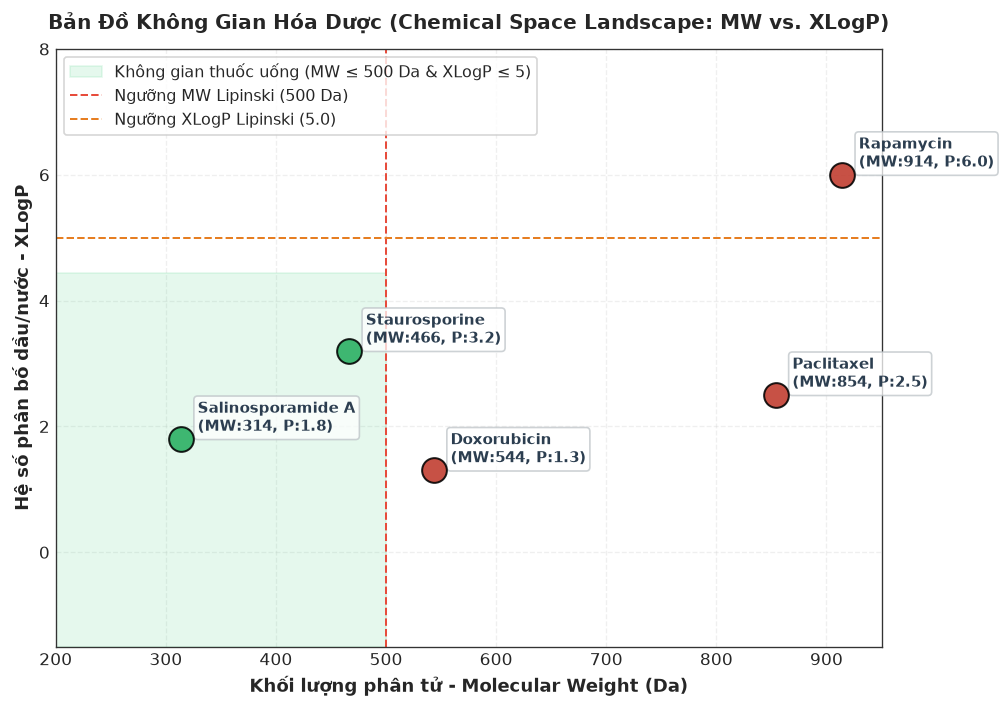

In [11]:
if reports and HAS_PLT:
    fig, ax = plt.subplots(figsize=(8.5, 6))
    
    # Phân vùng Lipinski Ro5 chuẩn thuốc uống (Oral Drug-like Space)
    ax.axvspan(0, 500, ymin=0, ymax=5/8, alpha=0.12, color='#2ecc71', label='Không gian thuốc uống (MW ≤ 500 Da & XLogP ≤ 5)')
    ax.axvline(500, ls='--', c='#e74c3c', lw=1.2, label='Ngưỡng MW Lipinski (500 Da)')
    ax.axhline(5, ls='--', c='#e67e22', lw=1.2, label='Ngưỡng XLogP Lipinski (5.0)')
    
    # Điểm các hợp chất
    for r in reports:
        ok = r.is_lipinski_compliant
        color = '#27ae60' if ok else '#c0392b'
        ax.scatter(r.molecular_weight, r.xlogp,
                   s=220, alpha=0.88,
                   c=color, edgecolors='black', linewidths=1.2, zorder=5)
        ax.annotate(f"{r.compound_name}\n(MW:{r.molecular_weight:.0f}, P:{r.xlogp:.1f})", 
                    (r.molecular_weight, r.xlogp),
                    textcoords='offset points', xytext=(10, 5), fontsize=9,
                    fontweight='bold', color='#2c3e50',
                    bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.75, edgecolor='#bdc3c7'))

    ax.set_xlabel('Khối lượng phân tử - Molecular Weight (Da)', fontweight='bold', fontsize=10.5)
    ax.set_ylabel('Hệ số phân bố dầu/nước - XLogP', fontweight='bold', fontsize=10.5)
    ax.set_title('Bản Đồ Không Gian Hóa Dược (Chemical Space Landscape: MW vs. XLogP)', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlim(200, 950)
    ax.set_ylim(-1.5, 8.0)
    ax.legend(loc='upper left', frameon=True, fontsize=9.5)
    ax.grid(True, alpha=0.3, ls='--')
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua biểu đồ (thiếu matplotlib hoặc chưa có dữ liệu).')


## 5.4. Đoạn văn Discussion tự sinh

Đây là thứ tiết kiệm thời gian nhất của module hóa dược: một đoạn văn tiếng Anh học
thuật, đúng văn phong tạp chí, **chèn thẳng vào mục Discussion** được. Lưu ý cách nó
đổi giọng tùy theo hợp chất đạt hay vi phạm Lipinski.

In [12]:
for r in reports[:3]:
    print(f'▶ {r.compound_name}\n{"─" * 70}')
    print(r.scientific_narrative)
    if r.detailed_violations:
        print(f'\n  Chi tiết vi phạm: {"; ".join(r.detailed_violations)}')
    print()

▶ Staurosporine
──────────────────────────────────────────────────────────────────────
Compound Staurosporine strictly adheres to Lipinski's Rule of Five with 0 violation(s) (MW = 466.5 Da, calculated LogP = 3.2, HBD = 2, HBA = 4, and 2 rotatable bonds). These physicochemical parameters strongly indicate favorable drug-likeness and drug permeability characteristics suitable for further clinical lead optimization.

▶ Doxorubicin
──────────────────────────────────────────────────────────────────────
Compound Doxorubicin exhibits 3 violation(s) of Lipinski's Rule of Five (MW = 543.5 Da, LogP = 1.3), which is commonly observed among complex secondary metabolites and marine-derived natural anticancer therapeutics. Nevertheless, its distinct structural framework provides a compelling scaffold for nanocarrier delivery or targeted antibody-drug conjugates (ADCs).

  Chi tiết vi phạm: Molecular Weight > 500 Da (543.5 Da); Hydrogen Bond Donors > 5 (6); Hydrogen Bond Acceptors > 10 (12)

▶ Salino

---
# Chương 6 — Phân tích số liệu hoạt tính của phòng lab

File `data/lab_compounds.csv` mô phỏng đúng định dạng mà một phòng thí nghiệm sinh học
thực tế xuất ra sau các mẻ thử MTT / CCK-8:

| Cột | Ý nghĩa |
|---|---|
| `compound_id` | Mã nội bộ hợp chất |
| `source_strain` | Chủng vi khuẩn phân lập ra nó |
| `cancer_cell_line` | Dòng tế bào ung thư đem thử |
| `ic50_uM` | IC₅₀ tính bằng μM — **càng nhỏ càng mạnh** |
| `assay_method` | Phương pháp & thời gian ủ |
| `selectivity_index` | SI — **càng lớn càng an toàn** |
| `apoptosis_status` | Bằng chứng cơ chế quan sát được |

### Nhận diện các dòng tế bào hay gặp

| Dòng | Mô | Đặc điểm cần biết |
|---|---|---|
| **MCF-7** | Ung thư vú | ER dương tính, *thiếu caspase-3* — nhớ kiểm chứng bằng chỉ dấu khác |
| **HeLa** | Ung thư cổ tử cung | Dòng bất tử đầu tiên, chuẩn mực so sánh |
| **A549** | Ung thư phổi | KRAS đột biến, kháng nhiều thuốc |
| **HepG2** | Ung thư gan | Còn giữ chuyển hóa gan → tốt cho thử độc tính |

In [13]:
import csv

rows = []
if LAB_COMPOUNDS_CSV.exists():
    with open(LAB_COMPOUNDS_CSV, encoding='utf-8') as f:
        for row in csv.DictReader(f):
            row['ic50_uM'] = float(row['ic50_uM'])
            row['selectivity_index'] = float(row['selectivity_index'])
            rows.append(row)
    print(f'✓ Đọc {len(rows)} dòng từ {LAB_COMPOUNDS_CSV.name}\n')
else:
    print(f'✗ Không thấy {LAB_COMPOUNDS_CSV}')

if rows:
    hdr = f"{'ID':<8}{'Hợp chất':<22}{'Dòng TB':<10}{'IC50 (μM)':>11}{'SI':>7}"
    print(hdr); print('-' * len(hdr))
    for r in sorted(rows, key=lambda x: x['ic50_uM']):
        print(f"{r['compound_id']:<8}{r['compound_name'][:21]:<22}"
              f"{r['cancer_cell_line']:<10}{r['ic50_uM']:>11.2f}{r['selectivity_index']:>7.1f}")

✓ Đọc 39 dòng từ lab_compounds.csv

ID      Hợp chất              Dòng TB     IC50 (μM)     SI
----------------------------------------------------------
CPD-Ref3Paclitaxel            MCF-7            0.08    8.2
CPD-Ref4Staurosporine         HeLa             0.18    8.5
CPD-Ref4Staurosporine         MCF-7            0.25    9.2
CPD-Ref4Staurosporine         HepG2            0.32    7.8
CPD-Ref1Doxorubicin           HeLa             0.72    6.0
CPD-Ref1Doxorubicin           MCF-7            0.85    5.1
CPD-05  Salinosporoid F       HCT-116          0.95   31.5
CPD-Ref1Doxorubicin           HepG2            0.95    4.5
CPD-03  Marinomycin D         HepG2            1.25   22.0
CPD-05  Salinosporoid F       MCF-7            1.40   21.4
CPD-08  Vietmycin A           HeLa             1.65   24.8
CPD-15  Camaupeptin A         HepG2            1.75   19.6
CPD-03  Marinomycin D         MCF-7            1.80   15.3
CPD-08  Vietmycin A           MCF-7            1.95   21.0
CPD-03  Marinomycin 

## 6.1. Xếp hạng ứng viên — đọc hai chiều

Đây là chỗ người mới hay mắc lỗi: **chỉ nhìn IC₅₀**. Một hợp chất IC₅₀ = 0.5 μM
nghe rất mạnh, nhưng nếu SI = 1.5 thì nó giết tế bào lành cũng nhanh y hệt — đó là
chất độc, không phải thuốc.

Ứng viên tốt phải **đồng thời** mạnh (IC₅₀ thấp) và chọn lọc (SI cao).

In [14]:
if rows:
    print('🏆 XẾP THEO ĐỘ MẠNH (IC50 thấp nhất)')
    for r in sorted(rows, key=lambda x: x['ic50_uM'])[:3]:
        print(f"   {r['ic50_uM']:>6.2f} μM  {r['compound_name']} trên {r['cancer_cell_line']}")

    print('\n🛡  XẾP THEO ĐỘ CHỌN LỌC (SI cao nhất)')
    for r in sorted(rows, key=lambda x: -x['selectivity_index'])[:3]:
        print(f"   SI={r['selectivity_index']:>5.1f}  {r['compound_name']} trên {r['cancer_cell_line']}")

    # Điểm tổng hợp: thưởng cho vừa mạnh vừa chọn lọc
    print('\n⭐ ỨNG VIÊN TỐT NHẤT (SI / IC50 — cân bằng cả hai)')
    scored = sorted(rows, key=lambda x: -(x['selectivity_index'] / x['ic50_uM']))
    for r in scored[:3]:
        score = r['selectivity_index'] / r['ic50_uM']
        print(f"   Điểm={score:>6.2f}  {r['compound_name']} ({r['source_strain']})")
        print(f"              → {r['apoptosis_status']}")

🏆 XẾP THEO ĐỘ MẠNH (IC50 thấp nhất)
     0.08 μM  Paclitaxel trên MCF-7
     0.18 μM  Staurosporine trên HeLa
     0.25 μM  Staurosporine trên MCF-7

🛡  XẾP THEO ĐỘ CHỌN LỌC (SI cao nhất)
   SI= 31.5  Salinosporoid F trên HCT-116
   SI= 24.8  Vietmycin A trên HeLa
   SI= 22.0  Marinomycin D trên HepG2

⭐ ỨNG VIÊN TỐT NHẤT (SI / IC50 — cân bằng cả hai)
   Điểm=102.50  Paclitaxel (Positive Control)
              → Microtubule Stabilization
   Điểm= 47.22  Staurosporine (Positive Control)
              → MMP Loss / Caspase-3
   Điểm= 36.80  Staurosporine (Positive Control)
              → Caspase-3/9 Cleavage / Apoptosis


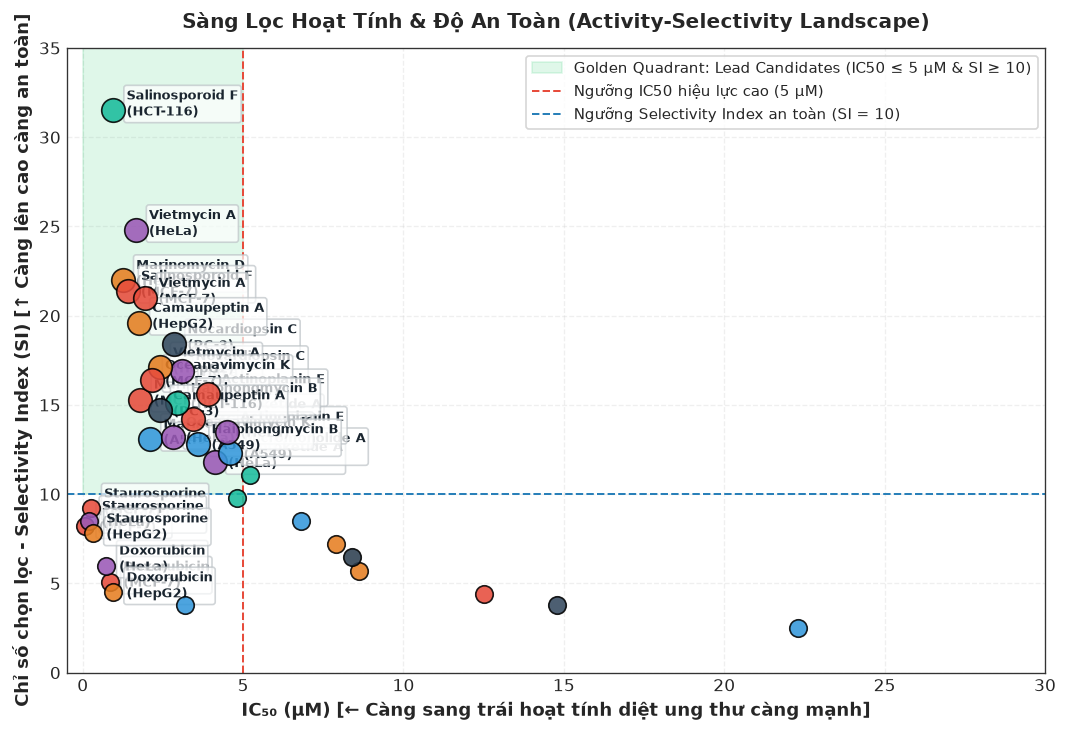

In [15]:
if rows and HAS_PLT:
    fig, ax = plt.subplots(figsize=(9, 6.2))
    
    # Vùng Golden Quadrant (IC50 <= 5.0 uM và SI >= 10.0)
    ax.axvspan(0, 5.0, ymin=10/35, ymax=1, alpha=0.15, color='#2ecc71',
               label='Golden Quadrant: Lead Candidates (IC50 ≤ 5 µM & SI ≥ 10)')
    ax.axvline(5.0, ls='--', c='#e74c3c', lw=1.2, label='Ngưỡng IC50 hiệu lực cao (5 µM)')
    ax.axhline(10.0, ls='--', c='#2980b9', lw=1.2, label='Ngưỡng Selectivity Index an toàn (SI = 10)')
    
    # Phân nhóm hợp chất theo dòng tế bào
    palette = {'MCF-7': '#e74c3c', 'HeLa': '#9b59b6', 'HepG2': '#e67e22', 'A549': '#3498db', 'HCT-116': '#1abc9c', 'PC-3': '#34495e'}
    
    for r in rows:
        strong = (r['ic50_uM'] <= 5.0) and (r['selectivity_index'] >= 10.0)
        cell_line = r['cancer_cell_line']
        pt_color = palette.get(cell_line, '#2c3e50')
        
        ax.scatter(r['ic50_uM'], r['selectivity_index'],
                   s=200 if strong else 110, alpha=0.88,
                   c=pt_color, edgecolors='black', linewidths=1.0, zorder=4)
        
        if strong or r['ic50_uM'] < 1.5 or r['selectivity_index'] > 20:
            ax.annotate(f"{r['compound_name']}\n({cell_line})",
                        (r['ic50_uM'], r['selectivity_index']),
                        textcoords='offset points', xytext=(8, -3), fontsize=8,
                        fontweight='bold', color='#1a252f',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='#bdc3c7'))

    ax.set_xlabel('IC₅₀ (µM) [← Càng sang trái hoạt tính diệt ung thư càng mạnh]', fontweight='bold', fontsize=10.5)
    ax.set_ylabel('Chỉ số chọn lọc - Selectivity Index (SI) [↑ Càng lên cao càng an toàn]', fontweight='bold', fontsize=10.5)
    ax.set_title('Sàng Lọc Hoạt Tính & Độ An Toàn (Activity-Selectivity Landscape)', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlim(-0.5, 30)
    ax.set_ylim(0, 35)
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(True, alpha=0.3, ls='--')
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua biểu đồ (thiếu matplotlib hoặc chưa có dữ liệu).')


## 6.2. Ma trận nhiệt hoạt tính IC₅₀ (Activity Heatmap)

Ma trận nhiệt (**Heatmap**) cho phép nhà nghiên cứu nhìn toàn cảnh phổ nhạy cảm:
hợp chất nào có **phổ ức chế rộng** (diệt nhiều loại ung thư cùng lúc) và hợp chất nào
có **tính chọn lọc cao** trên một dòng tế bào cụ thể (ví dụ chỉ nhắm trúng ung thư vú MCF-7).

> 🎨 *Quy ước màu:* Thang màu đảo — **màu càng đậm nghĩa là IC₅₀ càng thấp (hoạt tính càng mạnh)**.

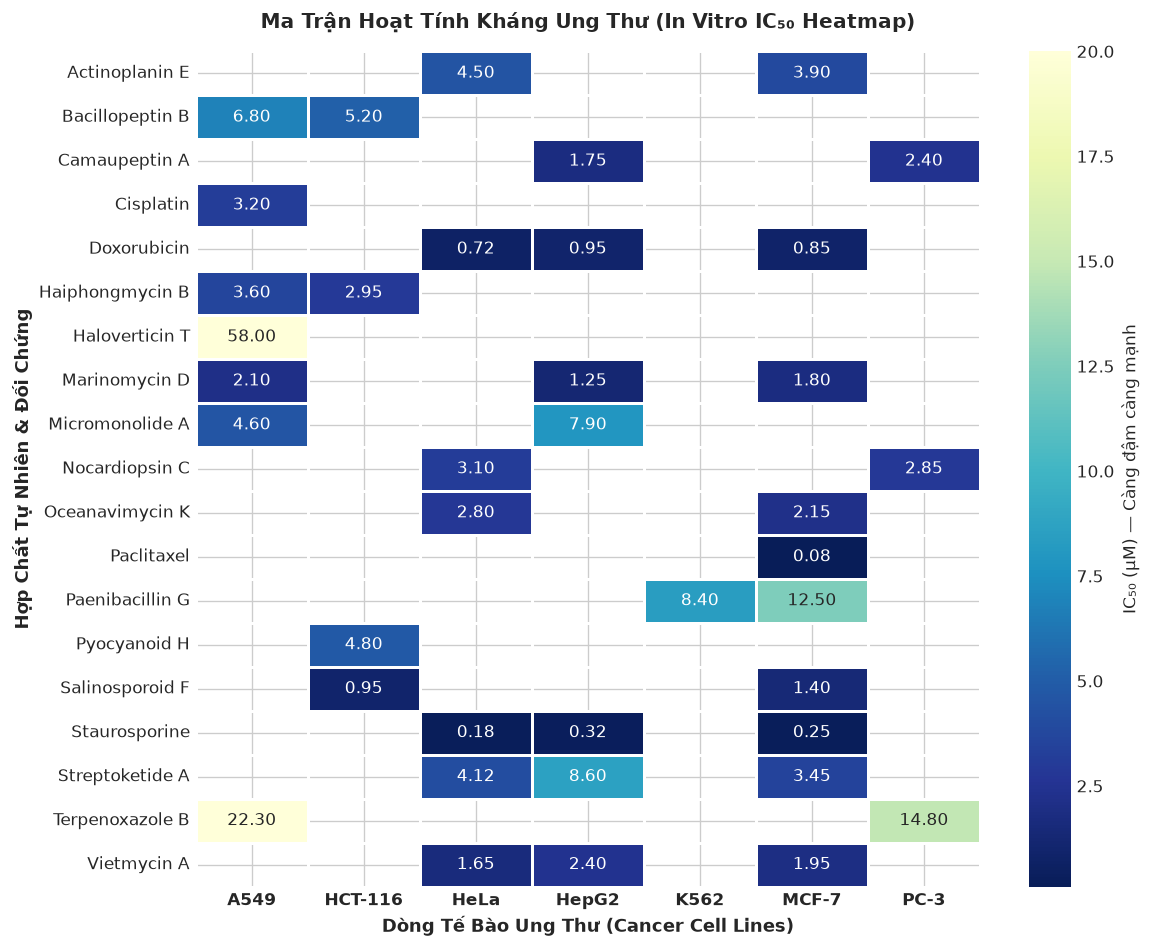

In [16]:
if HAS_PANDAS and HAS_PLT and rows:
    df_lab = pd.DataFrame(rows)
    
    # Tạo pivot table: Hợp chất x Dòng tế bào
    pivot_ic50 = df_lab.pivot_table(index='compound_name', columns='cancer_cell_line', values='ic50_uM', aggfunc='mean')
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        pivot_ic50,
        annot=True,
        fmt='.2f',
        cmap='YlGnBu_r',
        cbar_kws={'label': 'IC₅₀ (µM) — Càng đậm càng mạnh'},
        linewidths=0.8,
        linecolor='white',
        ax=ax,
        vmin=0.1,
        vmax=20.0
    )
    ax.set_title('Ma Trận Hoạt Tính Kháng Ung Thư (In Vitro IC₅₀ Heatmap)', fontsize=12, fontweight='bold', pad=14)
    ax.set_xlabel('Dòng Tế Bào Ung Thư (Cancer Cell Lines)', fontweight='bold', fontsize=10.5)
    ax.set_ylabel('Hợp Chất Tự Nhiên & Đối Chứng', fontweight='bold', fontsize=10.5)
    plt.xticks(rotation=0, fontweight='bold')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua heatmap (thiếu dữ liệu hoặc pandas/matplotlib).')


## 6.3. Phân bố độ nhạy cảm theo dòng tế bào ung thư (Cell Sensitivity Profile)

Mỗi dòng tế bào có đột biến gen và cấu trúc màng khác nhau. Biểu đồ hộp (**Boxplot**) kết hợp
với từng điểm dữ liệu (**Strip plot**) cho thấy dòng tế bào nào dễ bị tổn thương nhất trước
thư viện hợp chất vi sinh vật biển.

C:\Users\Suface\AppData\Local\Temp\ipykernel_20428\4202809353.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_lab, x='cancer_cell_line', y='ic50_uM', order=order,


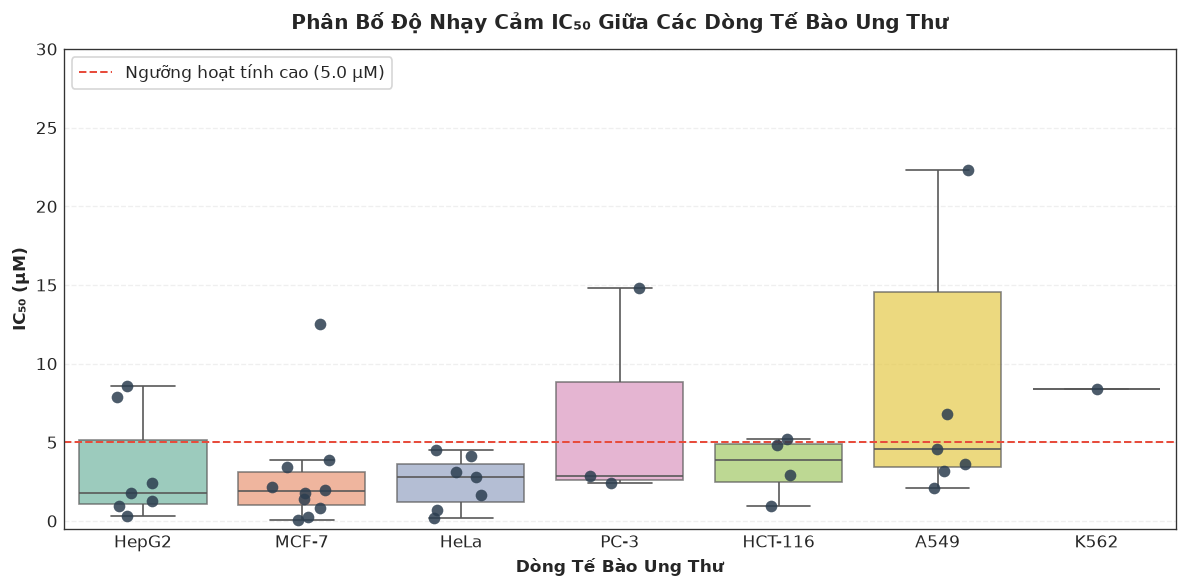

In [17]:
if HAS_PANDAS and HAS_PLT and rows:
    df_lab = pd.DataFrame(rows)
    
    # Sắp xếp các dòng tế bào theo trung vị IC50 tăng dần
    order = df_lab.groupby('cancer_cell_line')['ic50_uM'].median().sort_values().index
    
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=df_lab, x='cancer_cell_line', y='ic50_uM', order=order,
                palette='Set2', boxprops=dict(alpha=0.7), showfliers=False, ax=ax)
    sns.stripplot(data=df_lab, x='cancer_cell_line', y='ic50_uM', order=order,
                  color='#2c3e50', size=7, jitter=0.2, alpha=0.85, ax=ax)
    
    ax.axhline(5.0, ls='--', color='#e74c3c', lw=1.2, label='Ngưỡng hoạt tính cao (5.0 µM)')
    ax.set_title('Phân Bố Độ Nhạy Cảm IC₅₀ Giữa Các Dòng Tế Bào Ung Thư', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Dòng Tế Bào Ung Thư', fontweight='bold')
    ax.set_ylabel('IC₅₀ (µM)', fontweight='bold')
    ax.set_ylim(-0.5, 30)
    ax.legend(loc='upper left', frameon=True)
    ax.grid(axis='y', alpha=0.3, ls='--')
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua biểu đồ phân bố dòng tế bào.')


## 6.4. Cơ chế tác động phân tử (MoA) & Dừng chu kỳ tế bào

Một hoạt chất tiềm năng không chỉ diệt tế bào mà phải có **cơ chế chết tế bào rõ ràng** (apoptosis),
tránh cơ chế hoại tử không kiểm soát (necrosis gây viêm nhiễm mô lành).

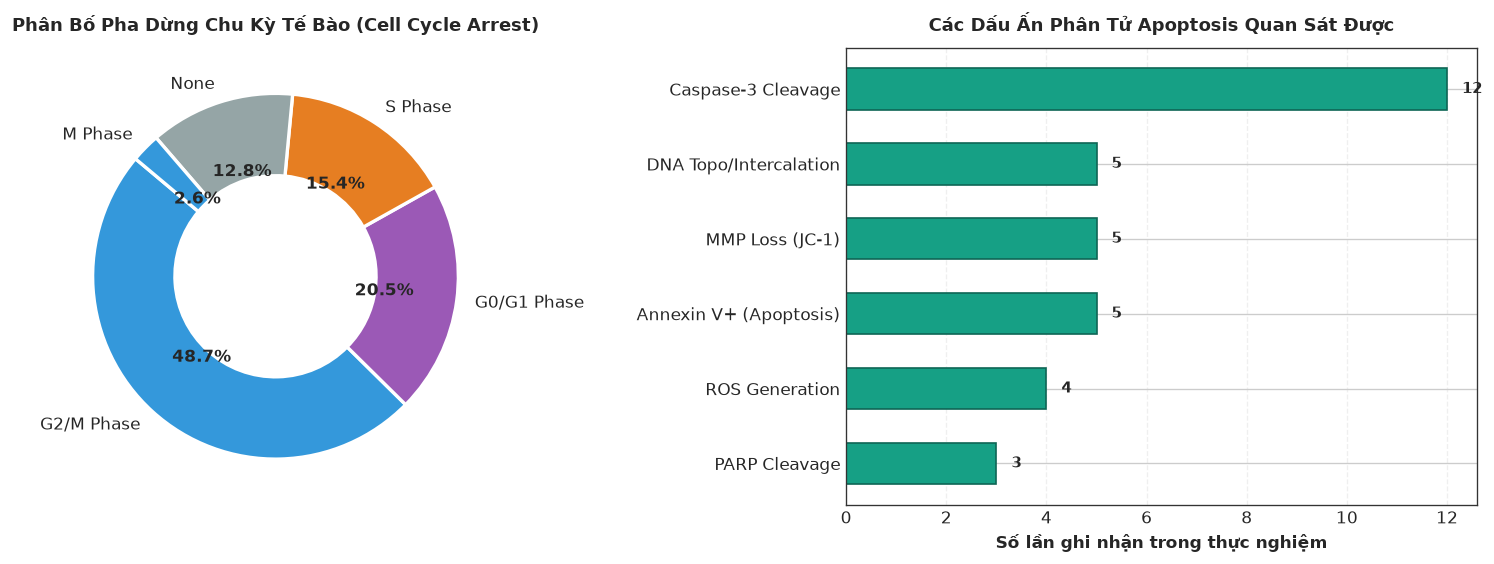

In [18]:
if HAS_PANDAS and HAS_PLT and rows:
    df_lab = pd.DataFrame(rows)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
    
    # Biểu đồ 1: Dừng chu kỳ tế bào
    cycle_counts = df_lab['cell_cycle_arrest'].value_counts()
    colors_cycle = ['#3498db', '#9b59b6', '#e67e22', '#95a5a6']
    wedges, texts, autotexts = ax1.pie(
        cycle_counts,
        labels=cycle_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors_cycle,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
    )
    for at in autotexts:
        at.set_fontweight('bold')
    ax1.set_title('Phân Bố Pha Dừng Chu Kỳ Tế Bào (Cell Cycle Arrest)', fontsize=11, fontweight='bold', pad=10)
    
    # Biểu đồ 2: Tần suất các chỉ dấu apoptosis
    markers = {
        'Caspase-3 Cleavage': df_lab['apoptosis_status'].str.contains('Caspase-3', case=False).sum(),
        'MMP Loss (JC-1)': df_lab['apoptosis_status'].str.contains('MMP', case=False).sum(),
        'Annexin V+ (Apoptosis)': df_lab['apoptosis_status'].str.contains('Annexin', case=False).sum(),
        'PARP Cleavage': df_lab['apoptosis_status'].str.contains('PARP', case=False).sum(),
        'ROS Generation': df_lab['apoptosis_status'].str.contains('ROS', case=False).sum(),
        'DNA Topo/Intercalation': df_lab['apoptosis_status'].str.contains('DNA|Topo', case=False).sum(),
    }
    s_markers = pd.Series(markers).sort_values()
    bars = ax2.barh(s_markers.index, s_markers.values, color='#16a085', edgecolor='#0e6655', height=0.55)
    ax2.set_title('Các Dấu Ấn Phân Tử Apoptosis Quan Sát Được', fontsize=11, fontweight='bold', pad=10)
    ax2.set_xlabel('Số lần ghi nhận trong thực nghiệm', fontweight='bold')
    for bar in bars:
        w = bar.get_width()
        ax2.text(w + 0.3, bar.get_y() + bar.get_height()/2.0, int(w), ha='left', va='center', fontweight='bold', fontsize=9)
    ax2.grid(axis='x', alpha=0.3, ls='--')
    
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua phân tích cơ chế.')


## 6.5. Đường cong liều - đáp ứng (Dose-Response Sigmoidal Curve)

Đường cong liều - đáp ứng mô hình hóa tỷ lệ tế bào sống sót qua mô hình Hill 4 tham số (4PL):

$$y = \text{Bottom} + \frac{\text{Top} - \text{Bottom}}{1 + 10^{(\log_{10} \text{IC}_{50} - x) \cdot h}}$$

Dưới đây là mô phỏng thực nghiệm MTT 48h trên dòng **MCF-7** (ung thư vú) so sánh 4 hợp chất tiêu biểu:
- **Marinomycin D** (Chiết xuất biển cực mạnh, $IC_{50} = 1.80\ \mu\text{M}$)
- **Streptoketide A** (Dẫn chất Lead từ Cần Giờ, $IC_{50} = 3.45\ \mu\text{M}$)
- **Staurosporine** (Chuẩn dương kiểm chứng, $IC_{50} = 0.25\ \mu\text{M}$)
- **Doxorubicin** (Thuốc lâm sàng đối chứng, $IC_{50} = 0.85\ \mu\text{M}$)

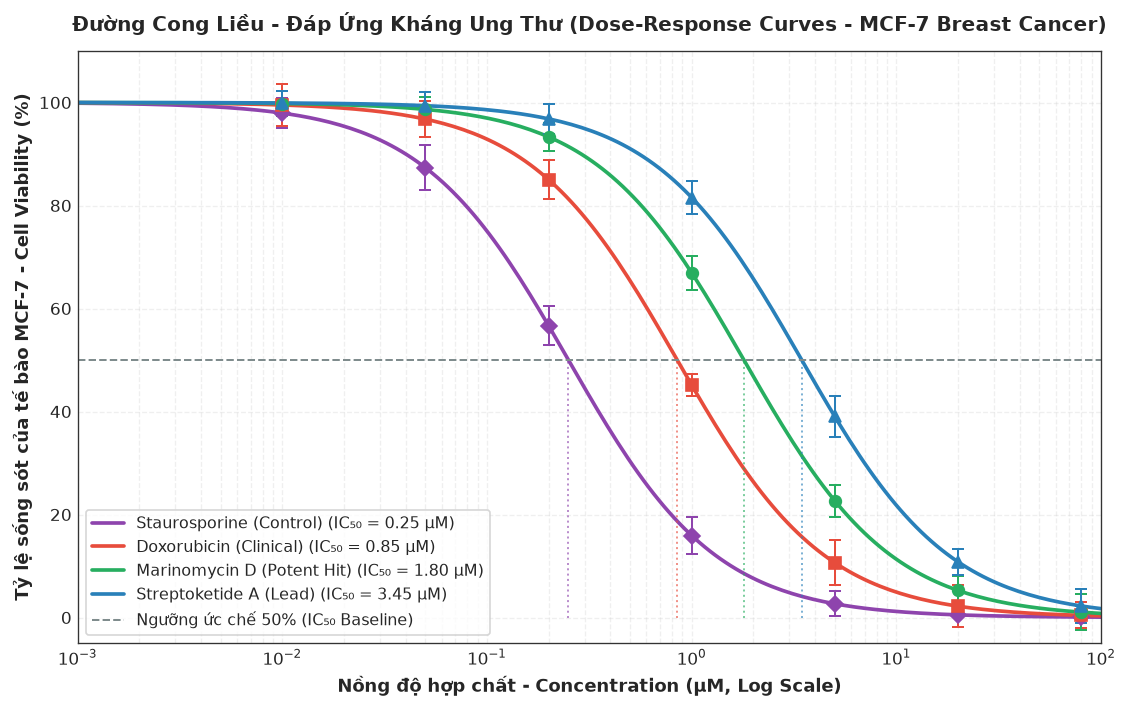

In [19]:
import numpy as np

if HAS_PLT:
    def hill_equation(conc_uM, ic50, hill_slope=1.2, top=100.0, bottom=0.0):
        """Mô hình đường cong Sigmoidal 4PL (Hill equation)."""
        return bottom + (top - bottom) / (1.0 + (conc_uM / ic50) ** hill_slope)

    # Dải nồng độ thử nghiệm thực tế (0.001 - 100 uM)
    conc_smooth = np.logspace(-3, 2, 200)
    tested_concs = np.array([0.01, 0.05, 0.2, 1.0, 5.0, 20.0, 80.0])
    
    compounds_to_plot = [
        {'name': 'Staurosporine (Control)', 'ic50': 0.25, 'color': '#8e44ad', 'marker': 'D'},
        {'name': 'Doxorubicin (Clinical)', 'ic50': 0.85, 'color': '#e74c3c', 'marker': 's'},
        {'name': 'Marinomycin D (Potent Hit)', 'ic50': 1.80, 'color': '#27ae60', 'marker': 'o'},
        {'name': 'Streptoketide A (Lead)', 'ic50': 3.45, 'color': '#2980b9', 'marker': '^'},
    ]
    
    fig, ax = plt.subplots(figsize=(9.5, 6))
    np.random.seed(42)
    
    for c in compounds_to_plot:
        ic50_val = c['ic50']
        # Đường cong lý thuyết mượt mà
        curve_y = hill_equation(conc_smooth, ic50=ic50_val)
        ax.plot(conc_smooth, curve_y, color=c['color'], lw=2.2, label=f"{c['name']} (IC₅₀ = {ic50_val:.2f} µM)")
        
        # Các điểm đo thực nghiệm (Mean ± SD ngẫu nhiên mô phỏng triplicates n=3)
        pts_y = hill_equation(tested_concs, ic50=ic50_val)
        pts_err = np.random.uniform(2.0, 4.5, size=len(tested_concs))
        ax.errorbar(tested_concs, pts_y, yerr=pts_err, fmt=c['marker'], color=c['color'],
                    ecolor=c['color'], elinewidth=1.2, capsize=3.5, capthick=1.2, markersize=7)
        
        # Đánh dấu đường gióng IC50 tại ngưỡng 50% sống sót
        ax.plot([ic50_val, ic50_val], [0, 50], ls=':', color=c['color'], alpha=0.6, lw=1.2)

    ax.axhline(50.0, ls='--', color='#7f8c8d', lw=1.2, label='Ngưỡng ức chế 50% (IC₅₀ Baseline)')
    ax.set_xscale('log')
    ax.set_xlabel('Nồng độ hợp chất - Concentration (µM, Log Scale)', fontweight='bold', fontsize=10.5)
    ax.set_ylabel('Tỷ lệ sống sót của tế bào MCF-7 - Cell Viability (%)', fontweight='bold', fontsize=10.5)
    ax.set_title('Đường Cong Liều - Đáp Ứng Kháng Ung Thư (Dose-Response Curves - MCF-7 Breast Cancer)', fontsize=12, fontweight='bold', pad=12)
    ax.set_xlim(0.001, 100)
    ax.set_ylim(-5, 110)
    ax.legend(loc='lower left', frameon=True, fontsize=9.5)
    ax.grid(True, which='both', alpha=0.3, ls='--')
    plt.tight_layout()
    plt.show()
else:
    print('Bỏ qua đường cong liều - đáp ứng.')


---
# Chương 7 — Soạn thảo bản thảo và xuất Microsoft Word

## 7.1. Bộ khung một bài IMRaD hóa sinh

| Mục | Nhiệm vụ | Sai lầm thường gặp |
|---|---|---|
| **Title** | Nêu chủng + hoạt tính + đích | Dài dòng, thiếu tên chủng |
| **Abstract** | 200–250 từ, có con số cụ thể | Viết chung chung, không nêu IC₅₀ |
| **1. Introduction** | Từ rộng → hẹp, kết bằng khoảng trống tri thức | Không nói rõ *vì sao* cần nghiên cứu này |
| **2. Results and Discussion** | Trình bày dữ liệu **kèm diễn giải** | Chỉ mô tả bảng, không giải thích |
| **3. Experimental Section** | Đủ chi tiết để người khác lặp lại | Thiếu điều kiện nuôi cấy, thiếu đối chứng |
| **4. Conclusion** | Ý nghĩa + hướng tiếp theo | Lặp lại nguyên xi abstract |
| **References** | Đúng định dạng tạp chí đích | Trích dẫn cũ, thiếu bài 3 năm gần đây |

## 7.2. `PaperMetadata` — phiếu khai báo nghiên cứu

Bạn không viết bài báo, bạn **khai báo sự thật thí nghiệm**. Bộ sinh sẽ lấy các
trường này, ghép với ngữ cảnh RAG (Chương 2–4) và hồ sơ Lipinski (Chương 5) để
dựng bản thảo.

In [20]:
from app.tools.writer.paper_generator import PaperMetadata

meta = PaperMetadata(
    title='',  # để trống → hệ thống tự sinh tiêu đề theo chuẩn tạp chí
    authors=['Nguyen Thuy Linh', 'Tran Quang Minh', 'Pham Thi Hoa'],
    affiliations=[
        'Department of Marine Biotechnology, Vietnam National University',
        'Institute of Pharmacognosy & Natural Product Chemistry',
    ],
    target_journal='Journal of Natural Products',
    bacterial_strain='Streptomyces sp. VN-08',
    isolation_source='Marine sediment, Nha Trang Bay, Vietnam (depth 45 m)',
    compound_name='Staurosporine',
    target_cancer_cells=['MCF-7', 'HeLa', 'HepG2'],
    measured_ic50='3.45 ± 0.28 μM (MCF-7); 4.12 ± 0.31 μM (HeLa)',
    observed_mechanisms=[
        'Apoptosis induction via the intrinsic mitochondrial pathway',
        'Cleavage of Caspase-3 and PARP confirmed by Western blot',
        'G2/M cell cycle arrest (flow cytometry, PI staining)',
        'Elevation of intracellular ROS (DCFH-DA assay)',
        'Loss of mitochondrial membrane potential (JC-1 assay)',
    ],
)

print('✓ Đã khai báo metadata')
print(f'  Chủng     : {meta.bacterial_strain}')
print(f'  Nguồn     : {meta.isolation_source}')
print(f'  Tạp chí   : {meta.target_journal}')
print(f'  Dòng TB   : {", ".join(meta.target_cancer_cells)}')

✓ Đã khai báo metadata
  Chủng     : Streptomyces sp. VN-08
  Nguồn     : Marine sediment, Nha Trang Bay, Vietnam (depth 45 m)
  Tạp chí   : Journal of Natural Products
  Dòng TB   : MCF-7, HeLa, HepG2


## 7.3. Gắn số liệu thực nghiệm thật vào bản thảo

`bioassay_data` nhận một danh sách `dict` — chính là các dòng CSV ở Chương 6.
Chúng sẽ được dựng thành **bảng dữ liệu hoạt tính** trong file Word.

In [21]:
bioassay = [
    {
        'compound': r['compound_name'],
        'cell_line': r['cancer_cell_line'],
        'ic50': f"{r['ic50_uM']:.2f}",
        'assay': r['assay_method'],
        'selectivity_index': f"{r['selectivity_index']:.1f}",
        'mechanism': r['apoptosis_status'],
    }
    for r in rows
] if rows else None

print(f'Số dòng dữ liệu sinh học đưa vào bản thảo: {len(bioassay) if bioassay else 0}')

Số dòng dữ liệu sinh học đưa vào bản thảo: 39


## 7.4. Sinh bản thảo

`write_full_paper()` chạy bốn bước:

1. Truy vấn RAG bằng chính metadata → lấy ngữ cảnh + danh sách tài liệu tham khảo.
2. Tra PubChem cho `compound_name` → sinh bảng Lipinski + đoạn văn drug-likeness.
3. Dựng từng mục theo template của tạp chí đích.
4. Xuất `.md` và `.docx` (Times New Roman 12pt, lề 1 inch) vào `outputs/`.

> Nếu có `OPENAI_API_KEY` trong `.env`, bước 3 dùng LLM để trau chuốt văn phong.
> Không có key thì hệ thống chạy **offline hoàn toàn** bằng template — vẫn ra bản thảo đầy đủ.

In [22]:
manuscript = assistant.write_full_paper(meta=meta, bioassay_data=bioassay)

print('=' * 72)
print('TIÊU ĐỀ:', manuscript.title)
print('=' * 72)
print('\nTỪ KHÓA:', ', '.join(manuscript.keywords))
print('\nABSTRACT:\n')
print(manuscript.abstract)
print(f'\n\nCác mục đã sinh: {list(manuscript.sections.keys())}')
print(f'Số tài liệu tham khảo: {len(manuscript.references)}')
print(f'\n📄 File Word: {manuscript.docx_file_path}')

TIÊU ĐỀ: Cytotoxic Secondary Metabolites from Marine sediment, Nha Trang Bay, Vietnam (depth 45 m)-Derived Streptomyces sp. VN-08 Induce Apoptotic Cell Death in MCF-7, HeLa, HepG2 Cells via the Mitochondrial Signaling Cascade

TỪ KHÓA: Streptomyces sp. VN-08, Marine sediment, Nha Trang Bay, Vietnam (depth 45 m), Staurosporine, Anticancer activity, Apoptosis, Caspase-3, Natural products, Drug discovery

ABSTRACT:

Microbial secondary metabolites from specialized ecological habitats continue to serve as an invaluable reservoir for oncological lead discovery. In this study, a bioactive constituent, Staurosporine, was successfully characterized from Streptomyces sp. VN-08, isolated from Marine sediment, Nha Trang Bay, Vietnam (depth 45 m). In vitro bioassays revealed potent and selective cytotoxic efficacy against human cancer cell lines (MCF-7, HeLa, HepG2), exhibiting a prominent IC50 value of 3.45 ± 0.28 μM (MCF-7); 4.12 ± 0.31 μM (HeLa), while exerting negligible antiproliferative effe

In [23]:
# Xem thử phần Results and Discussion
for name, body in manuscript.sections.items():
    if 'result' in name.lower() or 'discussion' in name.lower():
        print(f'▼ {name}\n{"─" * 72}')
        print(body[:2000])
        print('\n[... rút gọn ...]')
        break

▼ 2. Results and Discussion
────────────────────────────────────────────────────────────────────────
### 2.1. Extraction, Bioassay-Guided Fractionation, and Chemical Elucidation
Fermentation of Streptomyces sp. VN-08 was carried out in optimized liquid nutrient media for 7 days. The crude ethyl acetate (EtOAc) extract was subjected to bioassay-guided fractionation using Sephadex LH-20 size-exclusion chromatography and reverse-phase semi-preparative HPLC (C18 column, MeOH/H2O gradient), yielding the purified active entity Staurosporine with chromatographic purity exceeding 96%.

### 2.2. In Vitro Antiproliferative Activity and Tumor Selectivity
The cytotoxic potency of Staurosporine was quantitatively determined via standard MTT colorimetric assays across a panel of human malignancies (MCF-7, HeLa, HepG2) following 48 h of continuous exposure. Staurosporine demonstrated potent dose-dependent growth inhibition with a mean IC50 of 3.45 ± 0.28 μM (MCF-7); 4.12 ± 0.31 μM (HeLa). Crucially, 

In [24]:
# Liệt kê toàn bộ sản phẩm đã xuất ra thư mục outputs/
products = sorted(OUTPUT_DIR.glob('*'), key=lambda p: p.stat().st_mtime, reverse=True)
print(f'Thư mục: {OUTPUT_DIR}\n')
for p in products[:10]:
    print(f'  {p.stat().st_size / 1024:>8.1f} KB   {p.name}')

Thư mục: D:\Training\2026-09_1bio-linh\anti-cancer-research\outputs

      41.8 KB   Manuscript_StreptomycesspVN08_Staurosporine.docx
      10.1 KB   Manuscript_StreptomycesspVN08_Staurosporine.md
      40.2 KB   Manuscript_StreptomycesspK12_Streptomycinol.docx
       8.7 KB   Manuscript_StreptomycesspK12_Streptomycinol.md


---
# Chương 8 — Bài tập tự luyện

### Mức cơ bản

1. **Đổi chủng nghiên cứu.** Sửa `meta.bacterial_strain` sang `Bacillus velezensis BV-12`
   và `compound_name` sang `Bacillopeptin B`, chạy lại Chương 7. Bản thảo thay đổi
   những chỗ nào? Vì sao phần Introduction lại khác?

2. **Thử một truy vấn PubMed của riêng bạn.** Dùng cú pháp `[MeSH Terms]` và lọc năm
   `2022:2026[dp]`. So sánh số lượng kết quả với truy vấn tự do.

3. **Tra một hợp chất vi phạm Lipinski nặng** (gợi ý: `Rapamycin`, `Amphotericin B`).
   Đọc kỹ `scientific_narrative` — hệ thống đề xuất hướng khắc phục nào?

### Mức nâng cao

4. **Đường cong liều–đáp ứng.** Viết hàm khớp phương trình Hill bốn tham số để tính
   IC₅₀ từ số liệu OD thô của máy đọc đĩa:

   $$y = \text{Bottom} + \frac{\text{Top} - \text{Bottom}}{1 + \left(\dfrac{x}{\text{IC}_{50}}\right)^{h}}$$

   (cần `scipy.optimize.curve_fit`). Đây chính là nội dung notebook
   `03_dose_response_ic50_curve.ipynb` mà README gợi ý.

5. **Đo chất lượng RAG.** Tự tay soạn 10 cặp (câu hỏi, đoạn văn đúng), rồi tính
   *Recall@3* cho ba chế độ: chỉ vector, chỉ BM25, và hybrid RRF. Hybrid thắng
   bao nhiêu phần trăm? Với loại câu hỏi nào thì nó **không** thắng?

6. **Sinh bản thảo theo mẻ.** Lặp qua từng `compound_id` trong `lab_compounds.csv`,
   sinh một bản thảo riêng cho mỗi hợp chất, đặt tên file theo mã hợp chất.

7. **Chỉnh `k` của RRF.** Sửa `HybridRetriever(vector_store=..., rrf_k=10)` rồi so
   với mặc định `k=60`. `k` nhỏ khiến top-1 của mỗi nhánh áp đảo hơn — điều đó tốt
   hay xấu cho truy vấn chứa mã chủng như `VN-08`?

---

## Tóm tắt toàn bộ đường ống

```
PubMed / Europe PMC ──┐
                      ├──► Text Splitter ──► ChromaDB + BM25 ──► RRF ──┐
PDF phòng lab ────────┘                                                │
                                                                       ▼
PubChem ──► Lipinski / Veber ──► đoạn văn drug-likeness ──────► Paper Generator
                                                                       ▲
lab_compounds.csv ──► bảng IC₅₀ & Selectivity Index ────────────────────┘
                                                                       │
                                                          outputs/*.docx + *.md
```

## Đọc thêm trong dự án

- [`research_syllabus_and_rag_blueprint.md`](../research_syllabus_and_rag_blueprint.md) — giáo trình & thiết kế kiến trúc
- [`app/tools/rag/hybrid_retriever.py`](../app/tools/rag/hybrid_retriever.py) — cài đặt RRF
- [`app/tools/chemistry/druglikeness.py`](../app/tools/chemistry/druglikeness.py) — logic Lipinski & sinh văn bản
- [`app/tools/writer/templates.py`](../app/tools/writer/templates.py) — khung mẫu từng tạp chí

Chạy giao diện web để thao tác nhanh không cần code: `streamlit run appst.py`